# Function 1 - Week 8: Exploration review

Review the round 7 return received on **12 November 2026 at 03:39 GMT**. The official snapshot contains **10 starting observations and seven returns (17 rows)** across 2 input coordinates.

The latest signed output is **1.99731436342**, ranked **1/17**. The returned score improved the previous best of 2.17091292512e-14. The test at the previously fitted positive-source peak returned 1.99731436. The fitted component had a conditional peak height of about 0.7081. The observation establishes a high positive score at this input. Six queries remain per function, including Week 8.

Continue in [model predictions](model_predictions.ipynb) and the [week-level report](../report.md).


In [1]:
# Imports and shared helpers.
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's folder inside notebooks/.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from exploration_review_helpers import load_exploration_review, remaining_exploration_queries
from plot_helpers import (
    PLOT_CONFIG, plot_sampling_gaps,
    plot_observed_terrain, plot_fixed_exploration_progression,
)
function_shared_dir = shared_dir.parent / "Function_1" / "FunctionSpecificShared"
if str(function_shared_dir) not in sys.path:
    sys.path.insert(0, str(function_shared_dir))

from function_1_plots import plot_output_number_line
from function_1_model_helpers import signed_log
print("Python:", sys.executable)


Python: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
# Settings for this run. Keep the saved planning coordinates at full precision.
FUNCTION_NUMBER = 1
CURRENT_WEEK = 8
INPUT_COLUMNS = ["x1", "x2"]
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 10, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1}

ANALYSIS_DIR = Path.cwd().resolve()
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
TITLE = f"Function {FUNCTION_NUMBER} - Week {CURRENT_WEEK}"

FIRST_PLAN_WEEK = 2
PORTAL_DECIMALS = 6
PLANNED_QUERIES = pd.DataFrame([
    [0.15308205385104573, 0.13395525138390008],
    [0.7818589422435338, 0.0256071460565101],
    [0.12954929624948736, 0.822189245547224],
    [0.9121401448788213, 0.8617829948823881],
], columns=INPUT_COLUMNS)

SAMPLING_GAP_SIZE = (7.6 * 0.75, 6.1 * 0.75)
TERRAIN_SETTINGS = dict(
    relief=0.16, width=850, height=560,
    camera=dict(eye=dict(x=-1.05, y=-1.35, z=0.9)),
    show_reset=True,
)
TERRAIN_SCALE = 1e-200
TERRAIN_TICKS = (-1e-3, 0.0, 1e-14, 2.0)
WEEK_DIR = ANALYSIS_DIR.parent


In [3]:
# Validate the snapshot before plotting it.
review = load_exploration_review(
    DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))
print(review["report"])


,observation_id,source_round,x1,x2,y,output_rank
16,round-07,7,0.627916,0.628953,1.997314,1


Latest recorded submission: round 7 (1 new output).
Compared with 16 earlier observations (17 outputs in total).
Earlier output range: [-0.00550934555381, 2.17091292512e-14].

round-07: y = 1.99731436342 (positive); rank 1/17 (1 = highest output).
Inputs: x1 = 0.627916, x2 = 0.628953
New highest observed output. Largest absolute magnitude so far (363 times the earlier largest).


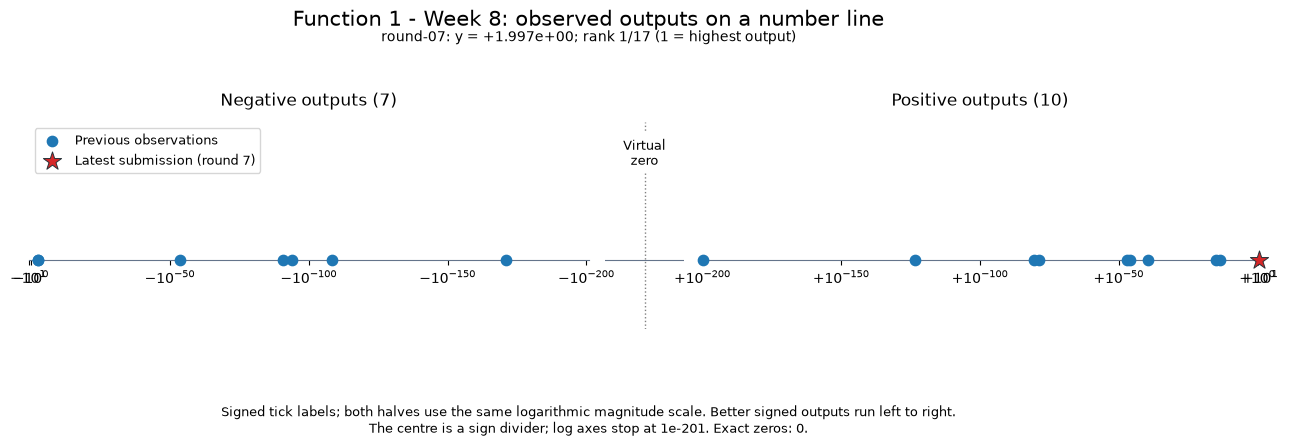

In [4]:
# Signed outputs on matching logarithmic magnitude scales.
plot_output_number_line(
    review, title=f"{TITLE}: observed outputs on a number line",
    save_to=FIGURES_DIR / "output-number-line.png",
)

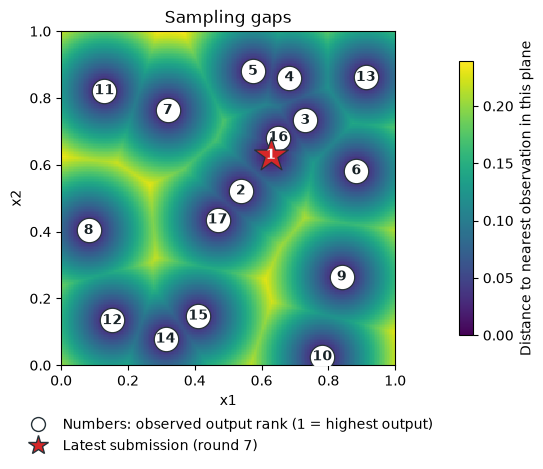

In [5]:
# Measured ranks and sampling gaps in the two-input square.
plot_sampling_gaps(
    review["plot_data"], pair=INPUT_COLUMNS,
    highlight=review["latest_mask"],
    highlight_label=f"Latest submission (round {review['latest_round']})",
    figsize=SAMPLING_GAP_SIZE, save_to=FIGURES_DIR / "sampling-gaps.png",
)

In [6]:
# The terrain joins observed signed-log heights; it does not fit a model.
terrain_fig = plot_observed_terrain(
    review["inputs"].to_numpy(), review["outputs"].to_numpy(),
    title=f"Function {FUNCTION_NUMBER}: observed-output terrain ({len(review['data'])} samples)",
    heights=signed_log(review["outputs"].to_numpy(), scale=TERRAIN_SCALE),
    height_axis=dict(title="Output y (signed log)", tickmode="array",
        tickvals=signed_log(TERRAIN_TICKS, scale=TERRAIN_SCALE),
        ticktext=[f"{value:.0e}" if value else "0" for value in TERRAIN_TICKS]),
    height_description="signed-log heights", save_to=FIGURES_DIR / "observed-output-terrain.html",
    **TERRAIN_SETTINGS,
)
terrain_fig.show(config={**PLOT_CONFIG, "responsive": TERRAIN_SETTINGS["width"] is None})

The following storyboard stops at completion of the Week 2–5 fixed plan. The round 6 and round 7 queries appear in the current coverage and terrain views above.

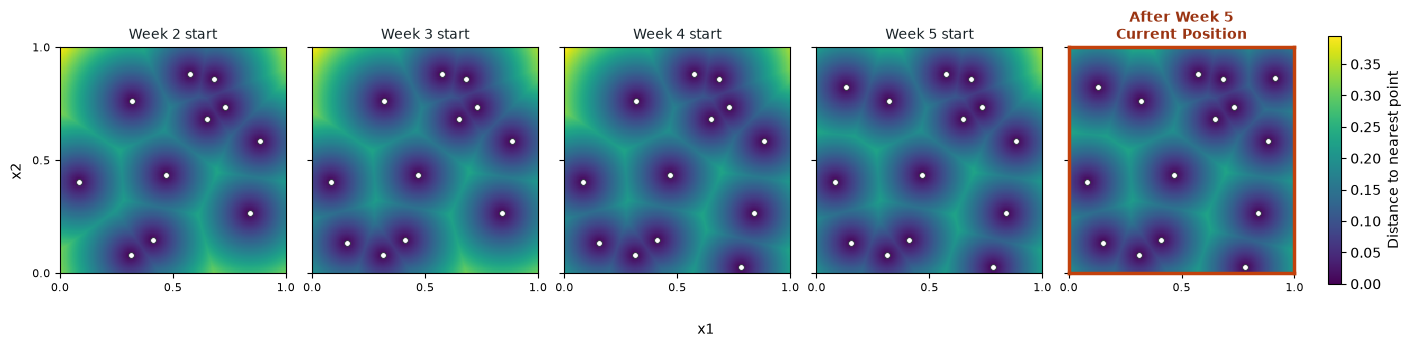

In [7]:
# Show the saved plan against recorded history; no optimisation is run here.
plot_fixed_exploration_progression(
    review["data"].loc[review["data"].source_round < 6], PLANNED_QUERIES, current_week=6,
    first_plan_week=FIRST_PLAN_WEEK,
    save_to=FIGURES_DIR / "fixed-exploration-progression.png",
)

In [8]:
# The completed shortlist returns an empty table; no next query is implied.
remaining_plan = remaining_exploration_queries(
    PLANNED_QUERIES, current_week=CURRENT_WEEK,
    first_plan_week=FIRST_PLAN_WEEK, precision=PORTAL_DECIMALS,
)
display(remaining_plan.style.format({
    column: f"{{:.{PORTAL_DECIMALS}f}}" for column in INPUT_COLUMNS
}))

,x1,x2,Portal input
Week,,,


In [9]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's own week folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))
from exploration_review_helpers import load_exploration_review
from observation_review_helpers import (
    prepare_weekly_observation_review, plot_input_profiles,
    plot_output_review, plot_round_progress,
)
from query_budget import remaining_queries

prepared = prepare_weekly_observation_review(review)


### Progress across completed rounds

The initial rows form one starting batch. Compare each return with the best known before that round.

In [10]:
display(prepared["progress"].set_index("stage")[["returned_y", "best_y", "change_vs_prior_best"]]
    .rename(columns={"returned_y": "Returned output", "best_y": "Best observed after stage",
                     "change_vs_prior_best": "Return minus previous best"})
    .style.format(formatter="{:.12g}", na_rep="Not applicable"))


,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,Not applicable,7.7108751145e-16,Not applicable
Round 1,-0.00550934555381,7.7108751145e-16,-0.00550934555381
Round 2,-4.0577449722e-109,7.7108751145e-16,-7.7108751145e-16
Round 3,1.97281177559e-200,7.7108751145e-16,-7.7108751145e-16
Round 4,-9.54589035235e-172,7.7108751145e-16,-7.7108751145e-16
Round 5,-1.38635890998e-94,7.7108751145e-16,-7.7108751145e-16
Round 6,2.17091292512e-14,2.17091292512e-14,2.09380417398e-14
Round 7,1.99731436342,1.99731436342,1.99731436342


### Saved Week 7 forecasts at the submitted input

Read the preserved final selection record without refitting. GP latent SD and neural seed SD describe different quantities. Function 1 uses signed-log prediction units; its raw output is also retained. UCB is a selection score.

In [11]:
# Compare only forecasts recorded before the round 7 observation existed.
stage_dir = shared_dir.parent.parent
selection_path = stage_dir / "submissions/Week_07/proposals.json"
if hashlib.sha256(selection_path.read_bytes()).hexdigest() != "23cdcf011d52c2684166b6f1a0aff2bf18d9d542383053c452e0707a3cfb5676":
    raise ValueError("The historical Week 7 selection record has changed.")
selection = next(row for row in json.loads(selection_path.read_text(encoding="utf-8"))["candidates"]
                 if row["function"] == FUNCTION_NUMBER)
actual_point = prepared["latest"][INPUT_COLUMNS].to_numpy(dtype=float)
if not np.array_equal(actual_point, np.asarray(selection["point"], dtype=float)):
    raise ValueError("Saved forecast coordinates do not match the returned query.")
actual_output = float(prepared["latest"][OUTPUT_COLUMN])
actual_target = float(signed_log(actual_output, scale=1e-200)) if FUNCTION_NUMBER == 1 else actual_output
historical_forecast = dict(selection["predictions"])
historical_forecast.update(
    source=selection_path.relative_to(stage_dir).as_posix(), source_sha256="23cdcf011d52c2684166b6f1a0aff2bf18d9d542383053c452e0707a3cfb5676",
    data_scope=selection["data_scope"], selection_policy=selection["selection_policy"],
    prediction_units=selection["prediction_units"], actual_output=actual_output,
    actual_in_prediction_units=actual_target,
    actual_minus_gp_mean=actual_target - historical_forecast["gp_mean"],
    actual_minus_neural_mean=actual_target - historical_forecast["neural_mean"],
)
display(pd.Series(historical_forecast))


positive_source_height                                                       0.708088
source_sigma                             [0.017678294379784333, 0.017678294379784333]
official_gp_cross_predictions       [{'model': 'Gaussian process', 'target': 'sign...
point                                                            [0.627916, 0.628953]
portal_input                                                        0.627916-0.628953
gp_mean                                                                   -218.183691
gp_latent_sd                                                               100.507026
gp_ucb_1_96                                                                -21.189921
neural_mean                                                                 21.395794
neural_seed_sd                                                              37.784641
neural_seed_predictions             [18.844403980117345, -15.048490256149087, 60.3...
inside_selected_gp_training_hull                      

### What the return adds

The returned score improved the previous best of 2.17091292512e-14. The test at the previously fitted positive-source peak returned 1.99731436. The fitted component had a conditional peak height of about 0.7081. The observation establishes a high positive score at this input.

In [12]:
# Full-precision review record; tiny signed outputs are never rounded to zero.
observation_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(review["data"]),
    "latest_id": prepared["latest"]["observation_id"],
    "latest_output": float(prepared["latest"][OUTPUT_COLUMN]),
    "latest_rank": int(review["latest_submissions"].iloc[0]["output_rank"]),
    "rank_definition": "1 = highest output",
    "best_id": prepared["incumbent"]["observation_id"],
    "best_observed_output": float(prepared["incumbent"][OUTPUT_COLUMN]),
    "positive_outputs": int((review["outputs"] > 0).sum()),
    "negative_outputs": int((review["outputs"] < 0).sum()),
    "exact_zeros": int((review["outputs"] == 0).sum()),
    "progress": prepared["progress"].fillna("not_applicable").to_dict(orient="records"),
    "official_history_comparison": prepared["neighbour_summary"],
    "historical_forecast": historical_forecast,
    "remaining_queries": remaining_queries(WEEK_DIR),
}
(ANALYSIS_DIR / "observation-review.json").write_text(
    json.dumps(observation_summary, indent=2, allow_nan=False) + "\n", encoding="utf-8")
print(json.dumps(observation_summary, indent=2))


{
  "function": 1,
  "week": 8,
  "observations": 17,
  "latest_id": "round-07",
  "latest_output": 1.9973143634157464,
  "latest_rank": 1,
  "rank_definition": "1 = highest output",
  "best_id": "round-07",
  "best_observed_output": 1.9973143634157464,
  "positive_outputs": 10,
  "negative_outputs": 7,
  "exact_zeros": 0,
  "progress": [
    {
      "source_round": 0,
      "stage": "Initial batch",
      "returned_y": "not_applicable",
      "best_y": 7.710875114502849e-16,
      "change_vs_prior_best": "not_applicable"
    },
    {
      "source_round": 1,
      "stage": "Round 1",
      "returned_y": -0.00550934555381189,
      "best_y": 7.710875114502849e-16,
      "change_vs_prior_best": -0.005509345553812661
    },
    {
      "source_round": 2,
      "stage": "Round 2",
      "returned_y": -4.0577449722040024e-109,
      "best_y": 7.710875114502849e-16,
      "change_vs_prior_best": -7.710875114502849e-16
    },
    {
      "source_round": 3,
      "stage": "Round 3",
      "re

### Course lifecycle for this review

1. **Define the goal and scope** — review round 7 for the project owner and prepare evidence for the Week 8 decision; success means a reconciled return and an accurate descriptive review.
2. **Gather the data** — use the retained 12 November results email, original cumulative attachments and independent official CSV snapshot.
3. **Explore the data** — inspect measured ranks, progress and coverage or full input profiles.
4. **Clean and preprocess the data** — validate dimensions, bounds, finite values and round counts; preserve all rows and full float64 precision.
5. **Select and engineer features** — retain the existing ordered input coordinates; no engineered features are required.
6. **Define the machine-learning task** — continuous black-box maximisation remains the task; this notebook provides descriptive evidence.
7. **Partition the data** — not applicable: no new model is fitted or validated in this observation review.
8. **Select and train candidate methods** — not applicable: any Week 8 model comparison is separate work.
9. **Evaluate and interpret the results** — compare the measured return with earlier outputs, the prior incumbent and the saved forecast where one informed selection.
10. **Deploy and iterate** — no deployment applies; carry this evidence into the next query review. Six query opportunities remain, including Week 8; this notebook submits no query.
